# 03 - Análisis de montos y oportunidades

¿Dónde se concentra el gasto estimado de las licitaciones de la muestra, y qué destaca el puntaje de oportunidad?

Este notebook trabaja con la muestra pública `data/sample/licitaciones_muestra.csv` (1.407 licitaciones, sin datos personales), así que se puede ejecutar sin ticket de la API.

Tres advertencias que condicionan todo lo que sigue, tomadas del notebook 02:

- Solo el 49,5 % de las licitaciones informa un monto estimado.
- La muestra reúne lo que la API devolvió al consultar unos pocos días de abril de 2026; no es un periodo completo ni una muestra aleatoria.
- El monto es una **estimación** del organismo comprador al publicar, no el monto adjudicado.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "..")

from app.services.scoring import ScoringConfig, score_licitaciones

ASSETS_DIR = Path("../assets")
MILLION = 1_000_000

df = pd.read_csv("../data/sample/licitaciones_muestra.csv", parse_dates=["fecha_publicacion", "fecha_cierre"])
print(f"Licitaciones: {len(df)}   Organismos: {df['organismo_nombre'].nunique()}   Regiones: {df['region_unidad'].nunique()}")

Licitaciones: 1407   Organismos: 489   Regiones: 16


## 1. Qué montos se pueden analizar

Se usan solo los montos en pesos chilenos y se descartan los menores a $1.000, que son valores de relleno.

In [2]:
clp = df[(df["moneda"] == "CLP") & df["monto_estimado"].ge(1000)].copy()
clp["monto_mm"] = clp["monto_estimado"] / MILLION

print(f"Licitaciones con monto en pesos utilizable: {len(clp)} de {len(df)} ({len(clp) / len(df):.1%})")
print(f"Monto estimado total: ${clp['monto_mm'].sum():,.0f} millones")
clp["monto_mm"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_frame("Monto (millones de $)")

Licitaciones con monto en pesos utilizable: 678 de 1407 (48.2%)
Monto estimado total: $176,403 millones


,Monto (millones de $)
count,678.0
mean,260.2
std,2756.9
min,0.5
25%,8.6
50%,24.6
75%,85.4
90%,276.9
99%,3352.2
max,70157.4


In [3]:
ordered = clp["monto_estimado"].sort_values(ascending=False)
total = ordered.sum()

print(f"La licitación más grande concentra el {ordered.iloc[0] / total:.1%} del monto total")
print(f"Las 10 más grandes concentran el {ordered.head(10).sum() / total:.1%}")
print(f"La mitad más pequeña de las licitaciones suma el {ordered.tail(len(ordered) // 2).sum() / total:.1%}")

largest = clp.nlargest(5, "monto_estimado")[["nombre", "organismo_nombre", "monto_mm"]].copy()
largest["nombre"] = largest["nombre"].str.slice(0, 70)
largest["monto_mm"] = largest["monto_mm"].round(0)
largest.rename(columns={"nombre": "Licitación", "organismo_nombre": "Organismo", "monto_mm": "Monto (millones de $)"})

La licitación más grande concentra el 39.8% del monto total
Las 10 más grandes concentran el 64.0%
La mitad más pequeña de las licitaciones suma el 1.9%


,Licitación,Organismo,Monto (millones de $)
1303,INMUNOGLOBULINA G HUMANA 5A10 GRAMOS FAM 10000...,CENTRAL DE ABASTECIMIENTO DEL SISTEMA NACIONAL...,70157.0
89,SERVICIO DE ASEO HOSPITALARIO PARA EL HDS,SERVICIO DE SALUD ORIENTE HOSPITAL DEL SALVADOR,7568.0
90,Convenio de Suministro de Insumos para Sistema...,SERVICIO DE SALUD ORIENTE HOSPITAL DEL SALVADOR,7088.0
773,CONTRATO DE SUMINISTRO SERVICIO DE ASEO PARA L...,I MUNICIPALIDAD DE PUERTO MONTT,6000.0
93,Convenio de Suministro de Insumos para Cirugía...,SERVICIO DE SALUD ORIENTE HOSPITAL DEL SALVADOR,4927.0


**Lectura.**

- Quedan 678 licitaciones con monto utilizable (48,2 % de la muestra), que suman unos $176.400 millones estimados.
- **El total está dominado por muy pocas licitaciones.** Una sola, una compra de inmunoglobulina de la Central de Abastecimiento del sistema de salud por $70.157 millones, es el 39,8 % del monto total. Las 10 mayores suman el 64,0 % y la mitad más pequeña de las licitaciones apenas el 1,9 %.
- Por eso el promedio ($260 millones) no describe nada: la licitación típica es de $24,6 millones (mediana) y tres de cada cuatro están bajo los $85,4 millones.

En las secciones siguientes, los totales dicen dónde está el dinero y las medianas dicen cómo es la licitación típica. Son dos preguntas distintas y aquí dan respuestas distintas.

## 2. Montos por región

Como el total está dominado por unas pocas licitaciones, la tabla muestra el monto total y también la mediana, que describe mejor a la licitación típica de cada región.

In [4]:
def summarize(group_column):
    grouped = clp.groupby(group_column)["monto_mm"]
    table = pd.DataFrame(
        {
            "Licitaciones con monto": grouped.size(),
            "Monto total (millones de $)": grouped.sum().round(0),
            "% del monto total": (grouped.sum() / clp["monto_mm"].sum() * 100).round(1),
            "Mediana (millones de $)": grouped.median().round(1),
        }
    )
    return table.sort_values("Monto total (millones de $)", ascending=False)


by_region = summarize("region_unidad")
by_region

,Licitaciones con monto,Monto total (millones de $),% del monto total,Mediana (millones de $)
region_unidad,,,,
Región Metropolitana de Santiago,231,121625.0,68.9,29.0
Región de los Lagos,36,13763.0,7.8,33.0
Región de Valparaíso,59,9778.0,5.5,26.1
Región del Biobío,70,6950.0,3.9,24.6
Región de Coquimbo,43,6686.0,3.8,26.3
Región de la Araucanía,58,5734.0,3.3,23.1
Región del Ñuble,28,3783.0,2.1,54.5
Región de Atacama,13,1619.0,0.9,16.0
Región del Maule,37,1569.0,0.9,13.2


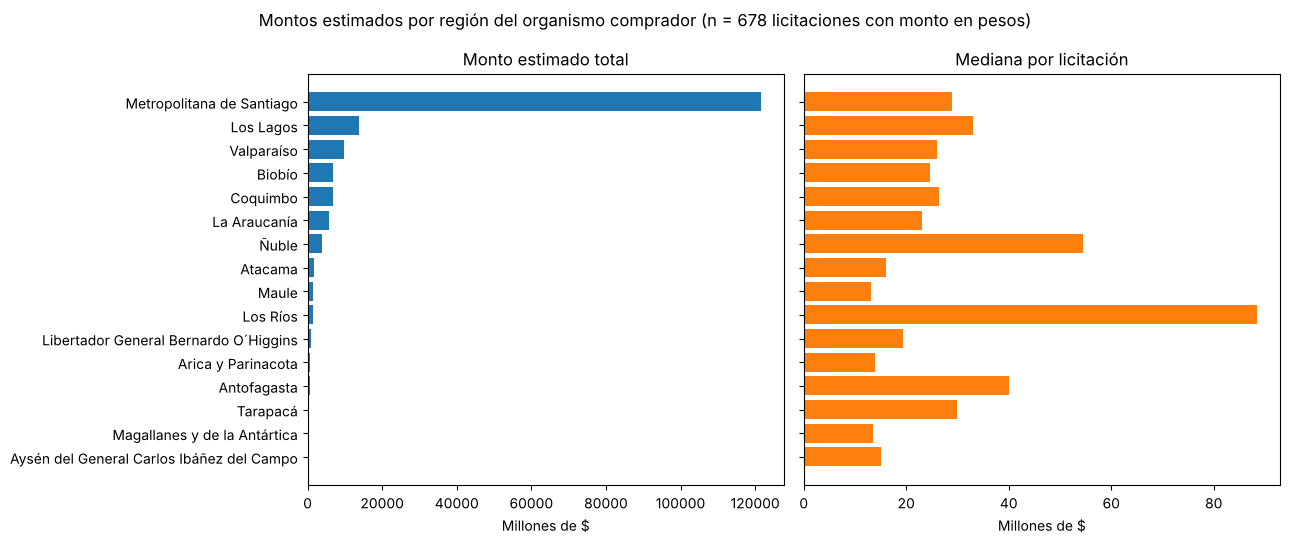

In [5]:
short_region = by_region.index.str.replace(r"^Región (del |de )?", "", regex=True).map(lambda name: name[:1].upper() + name[1:])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
axes[0].barh(short_region, by_region["Monto total (millones de $)"], color="#1f77b4")
axes[0].set_title("Monto estimado total")
axes[0].set_xlabel("Millones de $")
axes[0].invert_yaxis()
axes[1].barh(short_region, by_region["Mediana (millones de $)"], color="#ff7f0e")
axes[1].set_title("Mediana por licitación")
axes[1].set_xlabel("Millones de $")
fig.suptitle(f"Montos estimados por región del organismo comprador (n = {len(clp)} licitaciones con monto en pesos)")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "montos_por_region.png", dpi=150)
plt.show()

**Lectura.**

- La Región Metropolitana concentra el 68,9 % del monto estimado ($121.625 millones) con el 34 % de las licitaciones con monto (231 de 678). Pero más de dos tercios de ese total vienen de un solo organismo de alcance nacional con sede en Santiago: sin la Central de Abastecimiento, la región suma $38.202 millones.
- **Las medianas regionales son mucho más parejas que los totales**: la mayoría está entre $13 y $33 millones, y la Metropolitana ($29,0 millones) no destaca. El tamaño típico de una licitación no depende demasiado de la región.
- Los valores altos de Los Ríos ($88,5 millones) y Ñuble ($54,5 millones) salen de pocas licitaciones (14 y 28) y no deben leerse como un rasgo estable de esas regiones.
- Las tres regiones del norte que prioriza el perfil de ejemplo (Antofagasta, Tarapacá y Atacama) suman 36 licitaciones con monto y el 1,5 % del total.

## 3. Montos por organismo comprador

In [6]:
by_buyer = summarize("organismo_nombre")
print(f"Organismos con al menos un monto en pesos: {len(by_buyer)}")
print(f"Los 10 primeros concentran el {by_buyer['% del monto total'].head(10).sum():.1f} % del monto total")
by_buyer.head(10)

Organismos con al menos un monto en pesos: 282
Los 10 primeros concentran el 76.3 % del monto total


,Licitaciones con monto,Monto total (millones de $),% del monto total,Mediana (millones de $)
organismo_nombre,,,,
CENTRAL DE ABASTECIMIENTO DEL SISTEMA NACIONAL DE SERVICIO DE SALUD,9,83422.0,47.3,1630.9
SERVICIO DE SALUD ORIENTE HOSPITAL DEL SALVADOR,16,21793.0,12.4,198.1
HOSPITAL DE QUILPUE,3,6749.0,3.8,1162.6
I MUNICIPALIDAD DE PUERTO MONTT,5,6040.0,3.4,6.9
MINISTERIO DE OBRAS PUBLICAS DIREC CION GRAL DE OO PP DCYF,21,4105.0,2.3,68.3
SERVICIO LOCAL DE EDUCACIÓN PÚBLICA DE CHILOÉ,1,3729.0,2.1,3729.2
I MUNICIPALIDAD DE COQUIMBO,11,2995.0,1.7,24.0
ILUSTRE MUNICIPALIDAD TEODORO SCHMIDT,1,2208.0,1.3,2208.0
SERVICIO LOCAL DE EDUCACION DE PUERTO CORDILLERA,4,2020.0,1.1,396.0


**Lectura.**

- De los 282 organismos con algún monto en pesos, **los 10 primeros concentran el 76,3 % del total**, y uno solo, la Central de Abastecimiento del sistema de salud, el 47,3 % con 9 licitaciones.
- La concentración por organismo es todavía mayor que por región. El segundo comprador, el Hospital del Salvador, aporta el 12,4 % con 16 licitaciones.
- Más de la mitad de los organismos (156 de 282) aparece con una sola licitación con monto, así que para la mayoría no se puede decir nada sobre su patrón de compra.

## 4. Montos por rubro

El rubro de cada licitación es la categoría de primer nivel más frecuente entre sus ítems.

In [7]:
by_category = summarize("rubro_principal")
print(f"Rubros con al menos un monto en pesos: {len(by_category)}")
by_category.head(10)

Rubros con al menos un monto en pesos: 52


,Licitaciones con monto,Monto total (millones de $),% del monto total,Mediana (millones de $)
rubro_principal,,,,
Medicamentos y productos farmacéuticos,34,86866.0,49.2,110.2
Equipamiento y suministros médicos,82,21456.0,12.2,55.0
Servicios de limpieza industrial,27,17609.0,10.0,69.0
Servicios de construcción y mantenimiento,61,10941.0,6.2,49.7
"Servicios de transporte, almacenaje y correo",35,6477.0,3.7,30.0
"Servicios de defensa nacional, orden público y seguridad",10,5898.0,3.3,78.3
"Servicios profesionales, administrativos y consultorías de gestión empresarial",66,3037.0,1.7,10.5
"Salud, servicios sanitarios y alimentación",23,2942.0,1.7,46.2
"Tecnologías de la información, telecomunicaciones y radiodifusión",35,2478.0,1.4,14.0


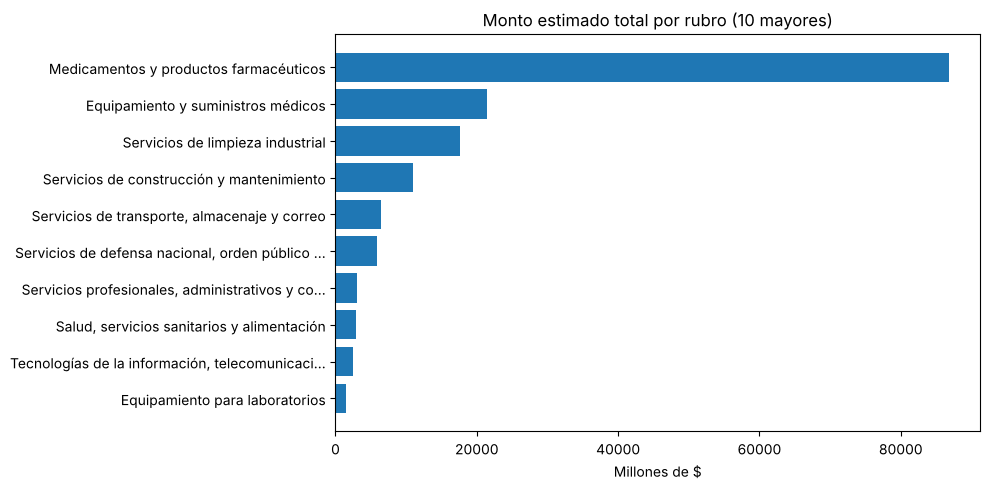

In [8]:
top_categories = by_category.head(10).iloc[::-1]
labels = [name if len(name) <= 48 else name[:45] + "..." for name in top_categories.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(labels, top_categories["Monto total (millones de $)"], color="#1f77b4")
ax.set_title("Monto estimado total por rubro (10 mayores)")
ax.set_xlabel("Millones de $")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "montos_por_rubro.png", dpi=150)
plt.show()

**Lectura.**

- **La salud domina el monto estimado.** Medicamentos y productos farmacéuticos concentra el 49,2 % con solo 34 licitaciones, y junto con equipamiento médico, servicios de salud y equipamiento de laboratorio llega al 63,9 %.
- Fuera de salud, los rubros con más monto son limpieza industrial (10,0 %), construcción y mantenimiento (6,2 %) y transporte (3,7 %).
- Los rubros con más licitaciones no son los de más monto: servicios profesionales tiene 66 licitaciones con monto, pero su mediana es de $10,5 millones y suma el 1,7 % del total.
- El rubro de construcción y mantenimiento, el más cercano al perfil de ejemplo del puntaje, tiene 61 licitaciones con monto y una mediana de $49,7 millones.

## 5. Puntaje de oportunidad

El puntaje suma puntos por reglas simples (palabras clave, estado, fecha de cierre, monto y región). Aquí se aplica el **perfil de ejemplo** del proyecto: servicios industriales y de construcción, con preferencia por Antofagasta, Tarapacá y Atacama.

Dos decisiones para que el resultado sea reproducible y comparable:

- La fecha de referencia se fija en el **6 de abril de 2026**, el día de la descarga. Sin fijarla, el puntaje cambiaría con cada ejecución, porque una regla premia a las licitaciones que aún no cierran.
- La muestra pública no incluye la descripción, así que las palabras clave se buscan solo en el nombre de la licitación.

In [9]:
REFERENCE_DATE = "2026-04-06"

profile = ScoringConfig()
scored = score_licitaciones(df, config=profile, reference_date=REFERENCE_DATE)

priority = scored["prioridad"].value_counts().reindex(["alta", "media", "baja"])
print(f"Licitaciones con alguna palabra clave en el nombre: {int(scored['contiene_keyword'].sum())}")
pd.DataFrame({"Licitaciones": priority, "%": (priority / len(scored) * 100).round(1)})

Licitaciones con alguna palabra clave en el nombre: 155


,Licitaciones,%
prioridad,,
alta,26,1.8
media,263,18.7
baja,1118,79.5


In [10]:
high = scored[scored["prioridad"] == "alta"].sort_values(["score", "monto_estimado"], ascending=False)
table = high[["nombre", "region_unidad", "estado", "monto_estimado", "score"]].head(10).copy()
table["nombre"] = table["nombre"].str.slice(0, 80)
table["monto_estimado"] = (table["monto_estimado"] / MILLION).round(1)
table.rename(
    columns={"nombre": "Licitación", "region_unidad": "Región", "estado": "Estado", "monto_estimado": "Monto (millones de $)", "score": "Puntaje"}
)

,Licitación,Región,Estado,Monto (millones de $),Puntaje
1140,SERVICIO DE MANO DE OBRA PARA REPARACION Y MAN...,Región del Ñuble,Publicada,365.0,90
1128,CONTRATO DE SUMINISTRO SERVICIO DE MANTENCIÓN ...,Región del Libertador General Bernardo O´Higgins,Publicada,22.0,90
394,Servicio de Mantenciones Carros de Arrastre De...,Región de Antofagasta,Publicada,32.0,80
246,ADQUISICION DE MATERIALES Y UTILES DIVERSOS PA...,Región del Ñuble,Publicada,NaN,80
342,MANTENCION Y REPARACION INFRAESTRUCTURA ESCOLAR,Región Metropolitana de Santiago,Publicada,NaN,80
593,MANTENCIÓN INFRAESTRUCTURA Y EQUIPOS INDUSTRIALES,Región Metropolitana de Santiago,Publicada,NaN,80
7,Servicio de obras de conservación esc José Agu...,Región de Coquimbo,Publicada,1223.5,70
984,SERVICIO DE RECOLECCION DE RESIDUOS SOLIDOS DO...,Región de los Lagos,Publicada,419.1,70
271,CONSTRUCCIÓN EST. PIEZOMÉTRICAS ETAPA 1 AÑO 2026,Región Metropolitana de Santiago,Publicada,170.0,70
467,REPARACIÓN AMBULANCIAS Y VEHÍCULOS C. FRUTA,Región del Libertador General Bernardo O´Higgins,Publicada,100.0,70


In [11]:
in_profile_regions = scored["region_unidad"].str.contains("Antofagasta|Tarapacá|Atacama")
print(f"Licitaciones en las tres regiones del perfil: {int(in_profile_regions.sum())}")
print(f"  de ellas, con prioridad alta: {int((in_profile_regions & (scored['prioridad'] == 'alta')).sum())}")
print(f"Prioridad alta fuera de esas regiones: {int((~in_profile_regions & (scored['prioridad'] == 'alta')).sum())}")
print(f"Prioridad alta sin monto informado: {int((scored['prioridad'].eq('alta') & scored['monto_estimado'].isna()).sum())}")

Licitaciones en las tres regiones del perfil: 95
  de ellas, con prioridad alta: 4
Prioridad alta fuera de esas regiones: 22
Prioridad alta sin monto informado: 6


**Lectura.**

- Con el perfil de ejemplo, 26 licitaciones (1,8 %) quedan con prioridad alta y 263 (18,7 %) con prioridad media. El puntaje reduce la lista de 1.407 a un grupo que una persona puede revisar.
- **La preferencia regional casi no influye en el resultado**: de las 26 con prioridad alta, 22 están fuera de las tres regiones del perfil. La regla regional suma 10 puntos y por sí sola no alcanza para llegar a prioridad alta; lo que decide son las palabras clave, el estado y la fecha de cierre.
- 6 de las 26 no informan monto, así que no se puede saber si superan el umbral de tamaño.
- **Lo que este análisis no puede decir es si el puntaje acierta.** No hay datos sobre a qué licitaciones se postuló ni cuáles se ganaron, así que los pesos no están validados. Las palabras clave también traen falsos positivos evidentes para un perfil industrial, como reparación de ambulancias o mantención de equipos dentales.

## 6. Conclusiones

1. **El monto estimado está muy concentrado.** Una licitación explica el 39,8 % del total, un organismo el 47,3 % y un rubro (medicamentos) el 49,2 %. Cualquier total por región, organismo o rubro está condicionado por unas pocas compras del sistema de salud.
2. **La licitación típica es pequeña y parecida en todo el país**: $24,6 millones de mediana, con medianas regionales entre $13 y $33 millones en la mayoría de las regiones.
3. **Para un proveedor, los totales engañan.** El rubro de construcción y mantenimiento tiene poco peso en el total (6,2 %), pero ofrece 61 licitaciones con una mediana de $49,7 millones, el doble de la mediana general.
4. **El puntaje sirve como filtro, no como ranking validado.** Reduce la muestra a 26 licitaciones de prioridad alta, pero la regla regional pesa poco y no hay datos para comprobar que el orden sea correcto.

### Limitaciones

- Solo el 48,2 % de las licitaciones tiene un monto en pesos utilizable. Si los organismos que no informan monto son distintos de los que sí lo hacen, estas conclusiones no se extienden al resto.
- La muestra corresponde a lo que la API devolvió al consultar unos pocos días de abril de 2026. No es representativa de un año ni permite ver tendencias.
- Los montos son estimaciones previas a la adjudicación y mezclan contratos de duraciones muy distintas (hay convenios de 36 y 72 meses).
- El rubro se asigna por la categoría más frecuente entre los ítems; una licitación con ítems de varios rubros queda clasificada en uno solo.
- En esta muestra pública las palabras clave se buscan solo en el nombre de la licitación. Con la descripción completa, que no se publica, el puntaje encuentra más coincidencias.